# 18a · Nearest neighbor classification

## The engineering question
Can labeled neighbors classify a new support request, and when should the classifier abstain?

**Learning outcomes:** compare a majority baseline with k-neighbor voting; isolate held-out labels; inspect the confusion matrix and neighbors; separate classification confidence from geometric proximity.

The fictional training set contains billing, account-access, and network requests. Test sentences are separately authored paraphrases plus an out-of-scope song request. The encoder is frozen, k=3 and similarity threshold 0.4 are fixed before test scoring. No model is fine-tuned. This is a small supervised decision layer on top of a learned representation, not evidence of general support-ticket accuracy.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("18a", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
import json

fixtures = json.loads((root() / "datasets/applications.json").read_text())

,text,expected,predicted,correct
0,Why was I billed twice this month?,billing,billing,True
1,Can you correct the amount on our receipt?,billing,abstain,False
2,The account rejects my sign in credentials,access,access,True
3,I am locked out after too many login attempts,access,access,True
4,Our office switch keeps losing its connection,network,network,True
5,The wireless network has frequent packet loss,network,network,True
6,Compose a birthday song,abstain,abstain,True


Why was I billed twice this month? -> billing
[{'text': 'The invoice includes a duplicate charge', 'label': 'billing', 'score': 0.5604832172393799}, {'text': 'Please refund the annual subscription payment', 'label': 'billing', 'score': 0.4464530348777771}, {'text': 'The renewal price is incorrect', 'label': 'billing', 'score': 0.41606348752975464}]
Can you correct the amount on our receipt? -> abstain
[{'text': 'The invoice includes a duplicate charge', 'label': 'billing', 'score': 0.386245995759964}, {'text': 'The renewal price is incorrect', 'label': 'billing', 'score': 0.36780107021331787}, {'text': 'Please refund the annual subscription payment', 'label': 'billing', 'score': 0.3669668734073639}]
The account rejects my sign in credentials -> access
[{'text': 'I cannot sign in with my password', 'label': 'access', 'score': 0.7420282363891602}, {'text': 'The single sign on login failed', 'label': 'access', 'score': 0.6601406335830688}, {'text': 'My login verification code expired', 'l

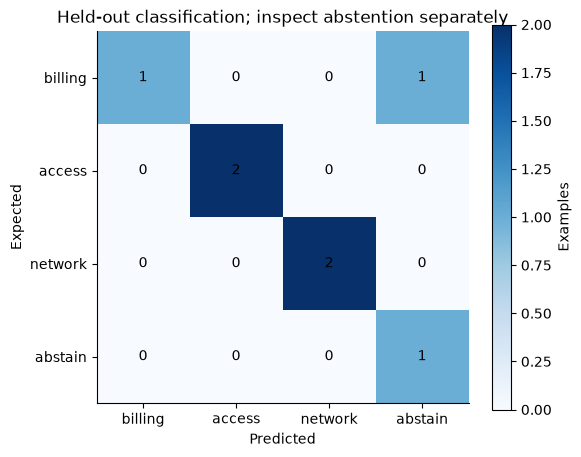

In [3]:
from collections import Counter
from sklearn.metrics import confusion_matrix
from vector_masterclass.models import embed
from vector_masterclass.applications import neighbor_predict
from vector_masterclass.retrieval import exact_search

cfg = fixtures["classification"]
texts, labels = zip(*cfg["train"])
vectors = embed(list(texts))
majority = sorted(Counter(labels), key=lambda label: (-Counter(labels)[label], label))[0]
rows = []
for (text, expected), query in zip(cfg["test"], embed([t for t, l in cfg["test"]])):
    predicted = neighbor_predict(query, vectors, labels, k=3, threshold=0.4)
    neighbors = exact_search(query, vectors, [str(i) for i in range(len(texts))], k=3)
    rows.append(
        {
            "text": text,
            "expected": expected,
            "predicted": predicted,
            "majority_baseline": majority,
            "correct": predicted == expected,
            "neighbors": [
                {"text": texts[int(i)], "label": labels[int(i)], "score": score}
                for i, score in neighbors
            ],
        }
    )
results = lesson.table(pd.DataFrame(rows))
display(results[["text", "expected", "predicted", "correct"]])
for row in rows:
    print(row["text"], "->", row["predicted"])
    print(row["neighbors"])
categories = ["billing", "access", "network", "abstain"]
cm = confusion_matrix(results.expected, results.predicted, labels=categories)
fig, ax = plt.subplots(figsize=(6, 5))
picture = ax.imshow(cm, cmap="Blues", vmin=0)
ax.set(
    xticks=range(4),
    xticklabels=categories,
    yticks=range(4),
    yticklabels=categories,
    xlabel="Predicted",
    ylabel="Expected",
    title="Held-out classification; inspect abstention separately",
)
for i in range(4):
    for j in range(4):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(picture, ax=ax, label="Examples")
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Majority voting can be wrong when nearby labels are mixed, while a similarity threshold can reject a correct low-similarity example. The held-out out-of-scope sentence probes abstention; it is not enough to calibrate all unknown requests. A point close to several billing examples is not automatically a calibrated billing probability.

**Exercise:** inspect the three neighbors of each error. Compare k=1 and k=5 on a newly defined development set before selecting another k. Explain why duplicating one training example can bias unweighted voting, and why balancing counts is different from representing the real deployment distribution.

Production checks should include per-class precision/recall, rare classes, label ambiguity, annotator agreement, source/customer separation, and drift. Similarity-based classification is useful when labels are scarce and explanations via examples help; a trained classifier may be cheaper or better once enough labels exist.

In [4]:
manifest = lesson.finish(
    {
        "no_exact_train_test_overlap": not set(texts) & {t for t, l in cfg["test"]},
        "all_test_examples_scored": len(results) == 7,
        "negative_case_present": bool(results.expected.eq("abstain").any()),
        "all_neighbors_from_training": all(len(r["neighbors"]) == 3 for r in rows),
    },
    observations={
        "k": 3,
        "threshold": 0.4,
        "test_accuracy": float(results.correct.mean()),
        "majority_accuracy": float(results.expected.eq(majority).mean()),
        "label_provenance": fixtures["provenance"],
    },
)

{
  "artifact": "artifacts/20261031T055950Z-6c6cc1/18a",
  "checks": {
    "no_exact_train_test_overlap": true,
    "all_test_examples_scored": true,
    "negative_case_present": true,
    "all_neighbors_from_training": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.